# 中证800口径四因子月度研究：从计算到结果读取

本文依次说明当前项目的四因子、综合评分、RankIC、调仓时点和成交成本. 前面的价格、评分与收益均为**教学示例**，不能作为研究结论；最后只读取项目已经生成的真实结果.

在 VS Code 中打开本文件，选择装有项目依赖的 Python 3.12 内核，按顺序运行单元. 本 notebook 不连接数据源，也不运行下载入口.

## 1. 导入项目中的函数

先找到项目根目录，再导入现有实现，这样后面的对照使用的就是主程序中的函数. `Path` 表示文件路径，`DataFrame` 是带行索引和列名的二维表.

In [1]:
from pathlib import Path
import sys

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "run_all.py").is_file()
             and (p / "src/factors.py").is_file()), None)
if root is None:
    raise FileNotFoundError("请从项目根目录或 notebooks 目录打开并运行本 notebook.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.factors import FACTOR_COLUMNS, build_signals
from src.evaluate import calculate_rank_ic
from src.backtest import transaction_cost, can_trade

pd.set_option("display.max_columns", 12)
print("项目:", "csi800-four-factor-backtest")
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__)

项目: csi800-four-factor-backtest
Python: 3.12.10 | pandas: 3.1.1


## 2. 从价格计算四个因子

动量需要取到当前观测之前第 252 个价格，因此准备 253 个价格点. 下面构造十只虚拟股票的教学表，每行是一只股票在一天的记录. `np.arange(253)` 生成从 0 到 252 的整数；循环中的公式只用于产生有变化的价格和换手率.

日期采用工作日教学网格，不是交易所日历. `adj_close` 表示示例复权价格，`turn` 表示换手率，`isST=0` 与 `tradestatus=1` 表示示例股票在当日非 ST 且正常交易.

In [2]:
dates = pd.bdate_range(end="2024-04-30", periods=253)
t = np.arange(len(dates))
parts = []
for j in range(10):
    parts.append(pd.DataFrame({
        "date": dates,
        "code": f"demo_{j + 1:02d}",
        "adj_close": 10 + 0.02 * (j + 1) * t + 0.1 * (j + 1) * np.sin(t / 8),
        "turn": 1 + j / 2 + 0.05 * np.cos(t / 7),
        "isST": 0,
        "tradestatus": 1,
    }))
teaching_prices = pd.concat(parts, ignore_index=True)
print("教学表形状（行数，列数）:", teaching_prices.shape)
display(teaching_prices.head(4))

教学表形状（行数，列数）: (2530, 6)


,date,code,adj_close,turn,isST,tradestatus
0,2023-05-12,demo_01,10.000000,1.050000,0,1
1,2023-05-15,demo_01,10.032467,1.049491,0,1
2,2023-05-16,demo_01,10.064740,1.047973,0,1
3,2023-05-17,demo_01,10.096627,1.045478,0,1


记 $P_t$ 为当日复权收盘价，$r_t=P_t/P_{t-1}-1$，下标按交易日计. 四个因子均按“数值越大，评分越高”定向：

| 因子 | 当前项目的定义 |
|---|---|
| 动量 | $P_{t-21}/P_{t-252}-1$，跳过最近 21 个交易日 |
| 反转 | $-(P_t/P_{t-21}-1)$ |
| 低波动 | 最近 60 个日收益率的样本标准差取负，使用 `ddof=1` |
| 换手率 | 最近 20 个交易日的换手率均值取负 |

先只计算第一只股票的最后一天. `loc` 按条件选行，`iloc` 按位置取值；`iloc[-1]` 是当前值，`iloc[-22]` 是向前 21 个观测的值. `pct_change(fill_method=None)` 遇到缺失价格不会先填补再计算收益.

In [3]:
one = teaching_prices.loc[teaching_prices["code"].eq("demo_01")]
p = one["adj_close"]
returns = p.pct_change(fill_method=None)
manual_factors = pd.Series({
    "momentum": p.iloc[-22] / p.iloc[-253] - 1,
    "reversal": -(p.iloc[-1] / p.iloc[-22] - 1),
    "low_volatility": -returns.iloc[-60:].std(ddof=1),
    "turnover": -one["turn"].iloc[-20:].mean(),
})
display(manual_factors.rename("demo_01 的教学因子值").to_frame())

,demo_01 的教学因子值
momentum,0.456348
reversal,-0.033297
low_volatility,-0.000637
turnover,-0.965450


把十只股票都列为该教学月末的成员，调用 `build_signals`. 实际项目每个月使用当时的指数成员，并在月末筛选非 ST、正常交易且四项因子均有效的股票.

每项因子在合格股票间取平均并列秩，再除以股票数；四项百分位秩取平均得到 `score`. Q1 分数最低，Q5 最高，各组内等权；基准是全部合格股票的等权组合. 本例恰有十只股票，每组两只，同分按代码排序.

In [4]:
members = pd.DataFrame({
    "signal_date": dates[-1],
    "code": teaching_prices["code"].unique(),
})
factor_signals = build_signals(teaching_prices, members)
module_factors = factor_signals.set_index("code").loc["demo_01", FACTOR_COLUMNS]
print("单股直接计算与模块结果一致:",
      np.allclose(manual_factors, module_factors.to_numpy(dtype=float)))

ordered = factor_signals.sort_values(["score", "code"]).copy()
ordered["group"] = np.repeat(["Q1", "Q2", "Q3", "Q4", "Q5"], 2)
display(ordered[["code", *FACTOR_COLUMNS, "score", "group"]].reset_index(drop=True))

单股直接计算与模块结果一致: True


,code,momentum,reversal,low_volatility,turnover,score,group
0,demo_10,4.563481,-0.087161,-0.001772,-5.46545,0.325,Q1
1,demo_09,4.107133,-0.085454,-0.001734,-4.96545,0.375,Q1
2,demo_08,3.650785,-0.083412,-0.001688,-4.46545,0.425,Q2
3,demo_07,3.194437,-0.080927,-0.001632,-3.96545,0.475,Q2
4,demo_06,2.738088,-0.077834,-0.001564,-3.46545,0.525,Q3
5,demo_05,2.281740,-0.073881,-0.001477,-2.96545,0.575,Q3
6,demo_04,1.825392,-0.068651,-0.001364,-2.46545,0.625,Q4
7,demo_03,1.369044,-0.061407,-0.001209,-1.96545,0.675,Q4
8,demo_02,0.912696,-0.050705,-0.000987,-1.46545,0.725,Q5
9,demo_01,0.456348,-0.033297,-0.000637,-0.96545,0.775,Q5


并列秩决定同值股票如何计分. 例如四个因子值 `[1, 2, 2, 4]` 中的两个 2 占据第 2、3 名，平均秩均为 2.5，百分位秩均为 `2.5 / 4`.

In [5]:
values = pd.Series([1, 2, 2, 4], name="教学因子值")
display(pd.DataFrame({
    "教学因子值": values,
    "平均秩": values.rank(method="average"),
    "百分位秩": values.rank(method="average", pct=True),
}))

,教学因子值,平均秩,百分位秩
0,1,1.0,0.250
1,2,2.5,0.625
2,2,2.5,0.625
3,4,4.0,1.000


## 3. 十只股票手算 RankIC

RankIC 比较信号排序与随后收益排序的相关程度. 另构造一个可以手算的独立教学例：评分从 0.1 到 1.0，收益排序每相邻两只互换. 这些评分和收益是人为指定的，不是上一节四因子产生的研究结果.

下表直接写出两组手工秩，再逐行计算秩差平方. 所有值均不并列.

In [6]:
r = np.arange(1, 11)
s = np.array([2, 1, 4, 3, 6, 5, 8, 7, 10, 9])
hand_table = pd.DataFrame({
    "code": [f"stock_{i:02d}" for i in r],
    "教学评分": r / 10,
    "教学下期收益": s / 100,
    "评分秩_r": r,
    "收益秩_s": s,
    "秩差平方": (r - s) ** 2,
})
display(hand_table)
print("秩差平方和:", hand_table["秩差平方"].sum())

,code,教学评分,教学下期收益,评分秩_r,收益秩_s,秩差平方
0,stock_01,0.1,0.02,1,2,1
1,stock_02,0.2,0.01,2,1,1
2,stock_03,0.3,0.04,3,4,1
3,stock_04,0.4,0.03,4,3,1
4,stock_05,0.5,0.06,5,6,1
5,stock_06,0.6,0.05,6,5,1
6,stock_07,0.7,0.08,7,8,1
7,stock_08,0.8,0.07,8,7,1
8,stock_09,0.9,0.10,9,10,1
9,stock_10,1.0,0.09,10,9,1


秩差平方和: 10


本例 $n=10$，十个秩差的平方都为 1，故 $\sum_i d_i^2=10$. **没有并列秩时**可直接使用

$$
\rho=1-\frac{6\sum_i d_i^2}{n(n^2-1)}
=1-\frac{6\times10}{10(10^2-1)}=\frac{31}{33}.
$$

调用 `calculate_rank_ic` 进行对照. 该函数要求四因子列与 `score` 均存在；本例只演示 `score`，所以四因子列设为缺失. 标签按**信号日期、股票代码**连接，下面故意倒置收益表的行序，结果仍应相同. 当前实现对有效配对取平均秩，再计算秩的 Pearson 相关，因此也适用于存在并列值的情形.

In [7]:
n = len(hand_table)
hand_ic = 1 - 6 * hand_table["秩差平方"].sum() / (n * (n ** 2 - 1))
ic_signals = pd.DataFrame({
    "date": pd.Timestamp("2024-01-31"),
    "code": hand_table["code"],
    "score": hand_table["教学评分"],
})
ic_signals[FACTOR_COLUMNS] = np.nan
labels = ic_signals[["date", "code"]].assign(forward_return=s / 100).iloc[::-1]
ic_result = calculate_rank_ic(ic_signals, labels)
score_ic = ic_result.loc[ic_result["factor"].eq("score")].iloc[0]
display(pd.DataFrame({"计算方式": ["手算公式", "项目 evaluate 输出"],
                      "RankIC": [hand_ic, score_ic["rank_ic"]]}))
print("有效配对数:", int(score_ic["n"]))
print("与手算 31/33 一致:", np.isclose(score_ic["rank_ic"], 31 / 33))

,计算方式,RankIC
0,手算公式,0.939394
1,项目 evaluate 输出,0.939394


有效配对数: 10
与手算 31/33 一致: True


## 4. 信号日期、成交日期和收益窗口

月末收盘才能形成信号，调仓安排在下一个交易日开盘，而不是月末当天. 下期收益标签从该开盘计算到再下个月首个交易日开盘，标签的 `date` 仍记信号日期. 不能把这段未来收益加入当期因子.

下面只列出说明所需的几个教学日期；实际程序使用完整的 BaoStock 交易日历. `searchsorted(..., side="right")` 找到严格晚于信号日的第一个日期. 若缺少退出开盘价，正式程序保留缺失标签.

In [8]:
teaching_calendar = pd.DatetimeIndex(pd.to_datetime([
    "2024-01-31", "2024-02-01", "2024-02-02", "2024-02-29", "2024-03-01"
]))
signal_day = pd.Timestamp("2024-01-31")
entry_day = teaching_calendar[teaching_calendar.searchsorted(signal_day, side="right")]
exit_month = entry_day.to_period("M") + 1
exit_day = teaching_calendar[teaching_calendar.to_period("M") == exit_month][0]
entry_open, exit_open = 100.0, 110.0  # 教学复权开盘价
display(pd.DataFrame({
    "信号日": [signal_day], "调仓开盘日": [entry_day], "标签退出开盘日": [exit_day],
    "教学开盘到开盘收益": [exit_open / entry_open - 1],
}))

,信号日,调仓开盘日,标签退出开盘日,教学开盘到开盘收益
0,2024-01-31,2024-02-01,2024-03-01,0.1


## 5. 成交成本与交易限制

项目对买入、卖出分别收取成交金额的 15 bps，即 $15/10000=0.15\%$. 两笔成交金额如果各为 10,000，合计费用才是 30；金额不同时分别计算. 对于只有多头的组合，如果只有 10,000 现金可用于买入，最大成交金额为 $10000/(1+0.0015)$，需给买入费用留出现金.

In [9]:
cash = 10_000.0
cost_bps = 15.0
buy_notional = cash / (1 + cost_bps / 10_000)
buy_fee = transaction_cost(buy_notional, cost_bps)
display(pd.DataFrame({
    "项目": ["买入成交 10000 的费用", "买卖各成交 10000 的合计费用",
             "现金 10000 的最大买入成交额", "该笔买入费用", "买入后剩余现金"],
    "金额": [transaction_cost(10_000, cost_bps), 2 * transaction_cost(10_000, cost_bps),
             buy_notional, buy_fee, cash - buy_notional - buy_fee],
}).round(6))

,项目,金额
0,买入成交 10000 的费用,15.000000
1,买卖各成交 10000 的合计费用,30.000000
2,现金 10000 的最大买入成交额,9985.022466
3,该笔买入费用,14.977534
4,买入后剩余现金,0.000000


### 多空账本（教学例）

为区分两条腿的盈亏，多空组合维护独立账本，以正股数表示多头、负股数表示空头. 每 1 元调仓前权益，多头和空头的目标名义金额各为 1 元，总敞口（gross exposure）为 200%. 它不是把已有 Q5、Q1 的净值直接相减. 建仓时两腿各付 15 bps，按成交价估值的建仓后净值为 `1 - 2 * 0.0015 = 0.997`.

下面完全是教学例：多头价格 10、空头价格 20，股数分别为 0.1、−0.05. 空头卖出所得计入现金，空头市值为负. 月内未调仓时股数不变，随后净值按“现金 + 带符号的持仓市值”计算，不每天重置两腿金额. 这里的建仓后值按成交价估值；正式每日净值按收盘价估值.

In [10]:
equity_before = 1.0
long_open, short_open = 10.0, 20.0
long_shares = equity_before / long_open
short_shares = -equity_before / short_open
fees = transaction_cost(1.0, 15.0) + transaction_cost(1.0, 15.0)
ls_cash = equity_before - long_shares * long_open - short_shares * short_open - fees
teaching_account = pd.DataFrame({
    "教学时点": ["建仓后按成交价估值", "月内另一时点，未调仓"],
    "多头价格": [10.0, 11.0], "空头价格": [20.0, 18.0],
    "多头股数": long_shares, "空头股数": short_shares, "现金": ls_cash,
})
teaching_account["权益"] = (ls_cash + long_shares * teaching_account["多头价格"]
                            + short_shares * teaching_account["空头价格"])
display(teaching_account.round(6))
print("教学初始费用:", fees)
print("初始总敞口 / 调仓前权益:", (abs(long_shares * long_open)
                                     + abs(short_shares * short_open)) / equity_before)

,教学时点,多头价格,空头价格,多头股数,空头股数,现金,权益
0,建仓后按成交价估值,10.0,20.0,0.1,-0.05,0.997,0.997
1,月内另一时点，未调仓,11.0,18.0,0.1,-0.05,0.997,1.197


教学初始费用: 0.003
初始总敞口 / 调仓前权益: 2.0


### 月度换手率（教学例）

换手率衡量实际成交规模相对账户权益的大小. 记实际买入金额为 `B`、实际卖出金额为 `S`、扣除本次费用前的调仓开盘权益为 `E`，单边换手率为 `(B + S) / (2 * E)`，对应输出列 `one_way_turnover`. 输出列 `turnover` 则为 `(B + S) / E`，是前者的两倍.

教学多空初始建仓时 `B = S = E = 1`，因此单边换手率为 1，总成交额口径为 2. 已安排调仓但没有实际成交的月份，两者都为 0；受阻订单不算成交. 分母使用调仓前权益 1，不能使用扣费后的 0.997.

In [11]:
teaching_turnover = pd.DataFrame({
    "教学场景": ["初始多空建仓", "已安排调仓但零成交"],
    "pre_trade_nav": [1.0, 1.197],
    "buy_notional": [1.0, 0.0], "sell_notional": [1.0, 0.0],
})
teaching_turnover["turnover"] = ((teaching_turnover["buy_notional"]
                                   + teaching_turnover["sell_notional"])
                                  / teaching_turnover["pre_trade_nav"])
teaching_turnover["one_way_turnover"] = teaching_turnover["turnover"] / 2
display(teaching_turnover)

,教学场景,pre_trade_nav,buy_notional,sell_notional,turnover,one_way_turnover
0,初始多空建仓,1.000,1.0,1.0,2.0,1.0
1,已安排调仓但零成交,1.197,0.0,0.0,0.0,0.0


涨跌停判断使用未复权的开盘价和昨收，不能代入前面的复权价格. 下面调用项目的 `can_trade`，展示普通主板、非 ST 股票的开盘成交限制：涨停不买，跌停不卖，停牌时买卖均受阻.

返回 `True` 只表示通过该函数的成交限制检查. Q1—Q5 和基准组合还会检查资金、持仓与复权开盘价；调仓先卖后买，卖出受阻的持仓保留，资金不足时同比例缩减可买订单.

In [12]:
base = {"code": "sh.600000", "isST": 0, "tradestatus": 1,
        "volume": 1_000_000, "preclose": 10.0}
cases = {
    "教学正常开盘": {**base, "open": 10.0},
    "教学涨停开盘": {**base, "open": 11.0},
    "教学跌停开盘": {**base, "open": 9.0},
    "教学停牌": {**base, "open": 10.0, "tradestatus": 0, "volume": 0},
}
gates = []
for name, row in cases.items():
    gates.append({"场景": name, "通过买入检查": can_trade(row, "buy", "2024-02-01"),
                  "通过卖出检查": can_trade(row, "sell", "2024-02-01")})
display(pd.DataFrame(gates))

,场景,通过买入检查,通过卖出检查
0,教学正常开盘,True,True
1,教学涨停开盘,False,True
2,教学跌停开盘,True,False
3,教学停牌,False,False


## 6. 读取正式运行生成的真实结果

前面的示例没有写入 `results/`. 下方只读 `run_all.py` 生成的真实表格：`mvp_performance.csv` 是净值表现，`mvp_ic_summary.csv` 是月度 IC 汇总，`mvp_execution_summary.csv` 是成交与成本汇总. `mvp_long_short_comparison.csv` 对照零成本的 `long_short_gross` 与含成本的 `long_short` 两个独立账户；`mvp_turnover.csv` 记录各组合每次调仓的实际成交金额与换手率，这里只显示前五行. 找不到文件时只提示缺失，不下载、不补造结果.

收益与回撤列采用小数表示，例如 `0.10` 代表 10%. `benchmark` 是同一合格股票池的等权组合. IC 的 `months` 是有效月数，`ic_ir` 是月度 IC 均值除以样本标准差，未年化. 换手率列 `one_way_turnover` 为单边口径，`turnover` 为总成交额口径.

In [13]:
for filename in ["mvp_performance.csv", "mvp_ic_summary.csv", "mvp_execution_summary.csv",
                 "mvp_long_short_comparison.csv", "mvp_turnover.csv"]:
    path = root / "results/tables" / filename
    if path.exists():
        print("读取真实结果:", path.relative_to(root))
        table = pd.read_csv(path)
        display(table.head() if filename == "mvp_turnover.csv" else table)
    else:
        print("尚未生成:", path.relative_to(root))

读取真实结果: results\tables\mvp_performance.csv


,portfolio,total_return,cagr,annual_vol,sharpe,max_drawdown,mean_monthly_turnover,mean_monthly_one_way_turnover,annualized_one_way_turnover
0,Q1,-0.297749,-0.044831,0.270474,-0.034285,-0.637407,1.041966,0.520983,6.251796
1,Q2,0.139279,0.017065,0.231555,0.188851,-0.489513,1.400646,0.700323,8.403873
2,Q3,0.275702,0.032101,0.207103,0.256289,-0.365227,1.451697,0.725848,8.710181
3,Q4,0.685202,0.070067,0.185722,0.457727,-0.343015,1.374279,0.687139,8.245674
4,Q5,0.493456,0.053425,0.164129,0.399428,-0.302784,0.915990,0.457995,5.495941
5,benchmark,0.418176,0.046379,0.205216,0.323749,-0.350347,0.103748,0.051874,0.622487
6,long_short,0.194575,0.023339,0.196214,0.215842,-0.428620,2.031628,1.015814,12.189769
7,long_short_gross,0.599945,0.062883,0.194645,0.410785,-0.402337,2.028429,1.014214,12.170572


读取真实结果: results\tables\mvp_ic_summary.csv


,factor,mean_rank_ic,ic_std,ic_ir,positive_fraction,months
0,momentum,0.023832,0.210968,0.112965,0.568421,95
1,reversal,0.018895,0.169958,0.111176,0.442105,95
2,low_volatility,0.073159,0.227837,0.321102,0.652632,95
3,turnover,0.070853,0.207154,0.342033,0.652632,95
4,score,0.081611,0.198728,0.410665,0.694737,95


读取真实结果: results\tables\mvp_execution_summary.csv


,portfolio,executed_orders,blocked_orders,total_notional,total_cost
0,Q1,22639,344,69.089494,0.103634
1,Q2,25402,337,121.098272,0.181647
2,Q3,25833,351,141.013050,0.211520
3,Q4,25181,312,156.938177,0.235407
4,Q5,21532,194,96.760947,0.145141
5,benchmark,75837,1038,10.323135,0.015485
6,long_short,43766,476,244.102882,0.366154
7,long_short_gross,43763,479,285.449948,0.000000


读取真实结果: results\tables\mvp_long_short_comparison.csv


,portfolio,total_return,cagr,annual_vol,sharpe,max_drawdown,...,mean_monthly_one_way_turnover,annualized_one_way_turnover,cost_bps,target_long_exposure,target_short_exposure,total_cost
0,long_short,0.194575,0.023339,0.196214,0.215842,-0.428620,...,1.015814,12.189769,15.0,1.0,-1.0,0.366154
1,long_short_gross,0.599945,0.062883,0.194645,0.410785,-0.402337,...,1.014214,12.170572,0.0,1.0,-1.0,0.000000


读取真实结果: results\tables\mvp_turnover.csv


,date,portfolio,pre_trade_nav,buy_notional,sell_notional,cost,turnover,one_way_turnover
0,2018-01-02,Q1,1.0,0.986111,0.0,0.001479,0.986111,0.493056
1,2018-01-02,Q2,1.0,0.998502,0.0,0.001498,0.998502,0.499251
2,2018-01-02,Q3,1.0,0.998502,0.0,0.001498,0.998502,0.499251
3,2018-01-02,Q4,1.0,0.979021,0.0,0.001469,0.979021,0.489510
4,2018-01-02,Q5,1.0,0.998502,0.0,0.001498,0.998502,0.499251


最后查看正式净值图. 它展示扣除成本后的 Q1—Q5 与等权基准；教学例中得到的 RankIC 不能替代这次完整研究的结论. 文件不存在时保留提示，待主线完成后重新运行本节即可读取真实输出.

读取真实净值图: results\figures\mvp_nav.png


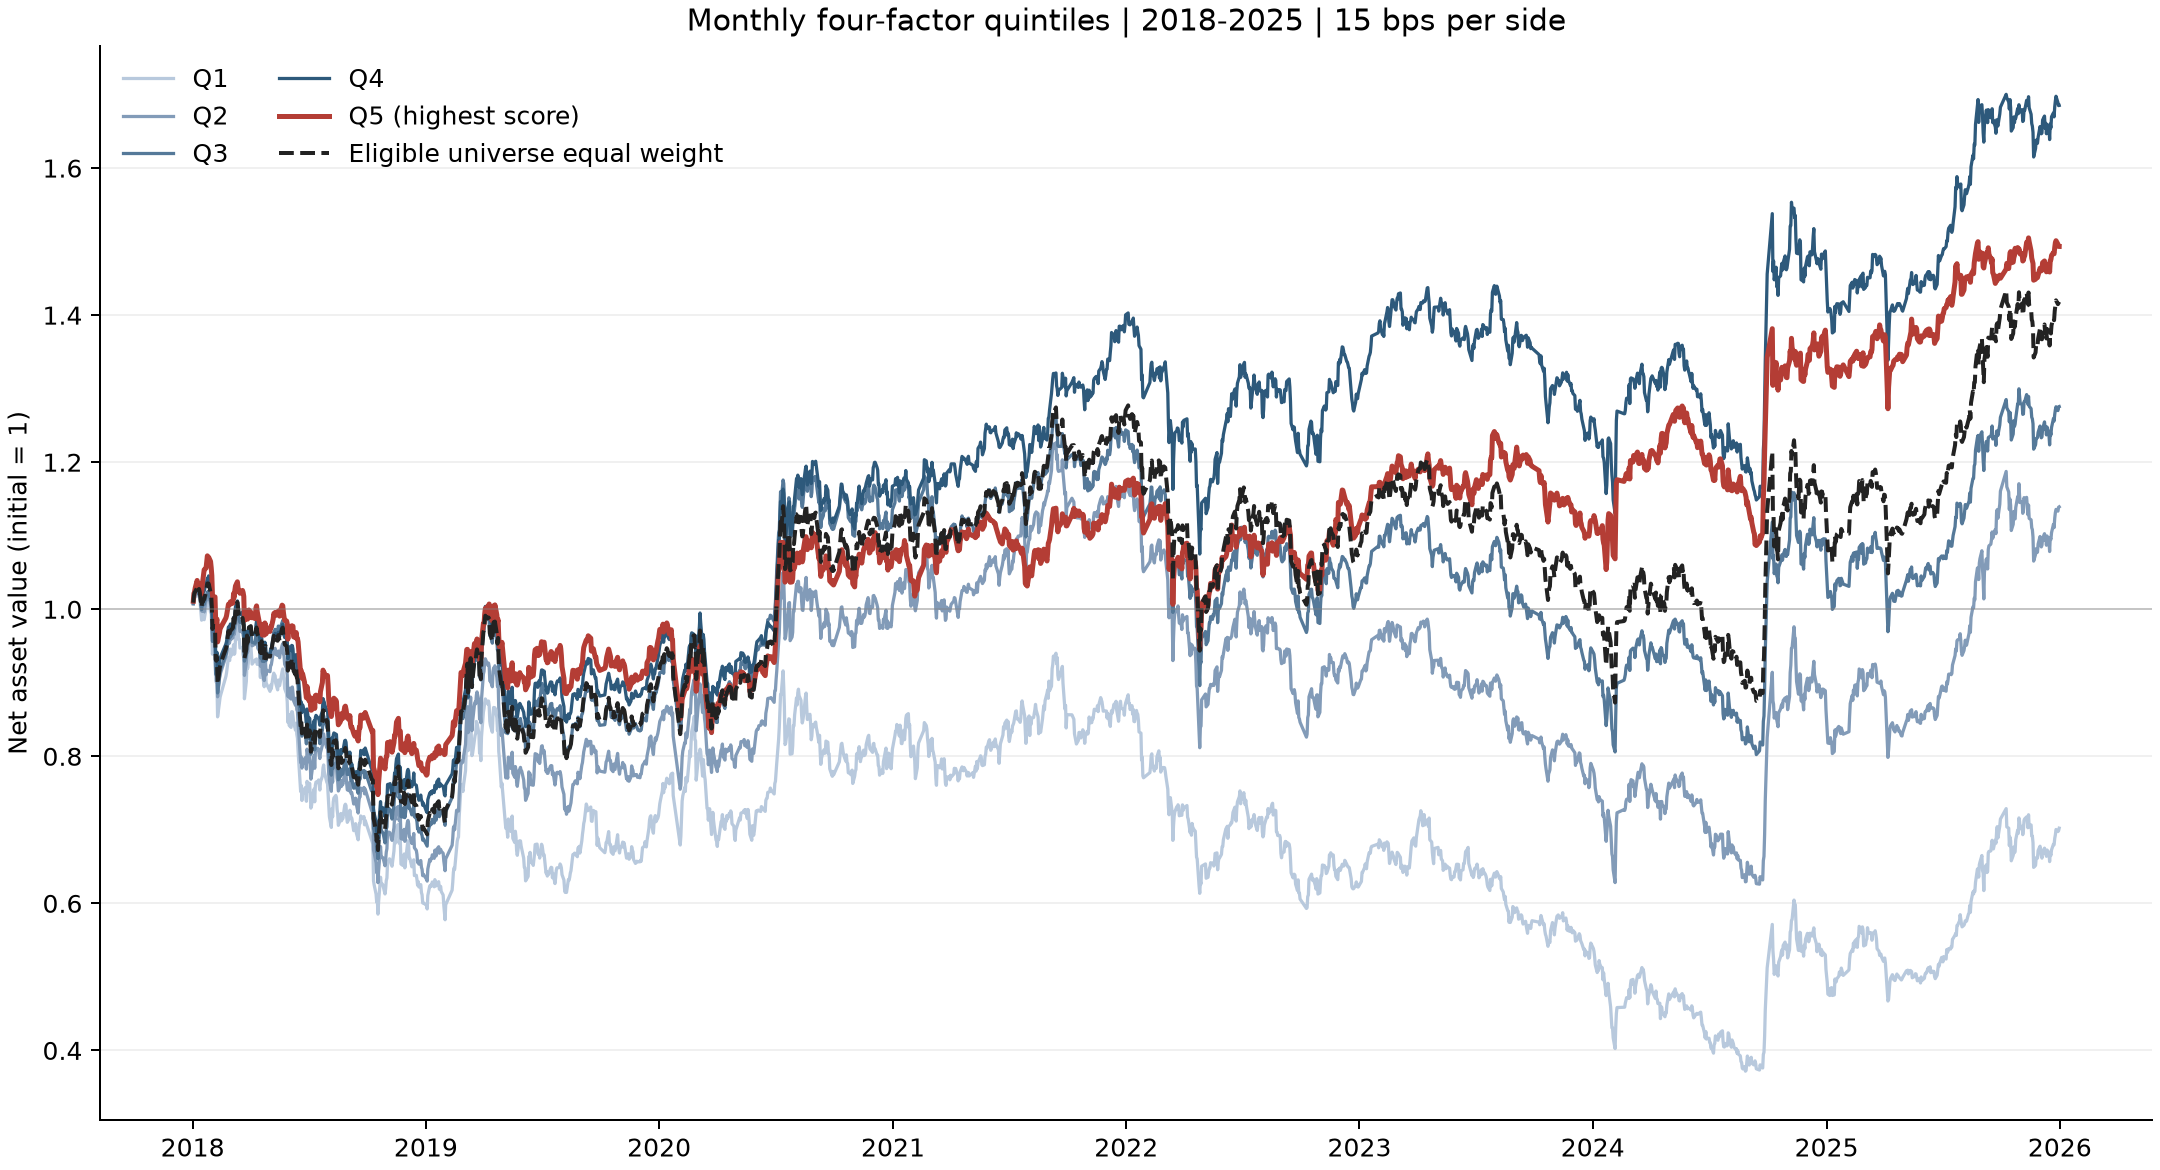

In [14]:
figure_path = root / "results/figures/mvp_nav.png"
if figure_path.exists():
    print("读取真实净值图:", figure_path.relative_to(root))
    display(Image(filename=str(figure_path)))
else:
    print("尚未生成:", figure_path.relative_to(root))